<a href="https://colab.research.google.com/github/Radhika-238/fcc-bikes-regression/blob/main/fcc_bikes_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [169]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import copy
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import RandomOverSampler
import tensorflow as tf
from sklearn.linear_model import LinearRegression

In [170]:
dataset_cols = ['bike_count', 'hour', 'temp', 'humidity', 'wind', 'visibility', 'dew_pt_temp', 'radiation', 'rain', 'snow', 'functional']

In [171]:
df = pd.read_csv('SeoulBikeData.csv', header = 1).drop(['Date', 'Seasons', 'Holiday'], axis = 1)
df.head()
df.columns = dataset_cols
df.head()
df['functional'] = (df['functional'] == 'Yes').astype(int)
df.head()
df = df[df['hour'] == 12]
df = df.drop(['hour'], axis = 1)
df.head()

,bike_count,temp,humidity,wind,visibility,dew_pt_temp,radiation,rain,snow,functional
12,449,1.7,23,1.4,2000,-17.2,1.11,0.0,0.0,1
36,479,4.3,41,1.3,1666,-7.8,1.09,0.0,0.0,1
60,333,5.8,85,1.7,349,3.4,0.43,0.0,0.0,1
84,393,-0.3,38,4.8,1823,-12.9,1.11,0.0,0.0,1
108,321,-2.3,25,0.0,1962,-19.7,0.00,0.0,0.0,1


how each features affect bikes count at noon

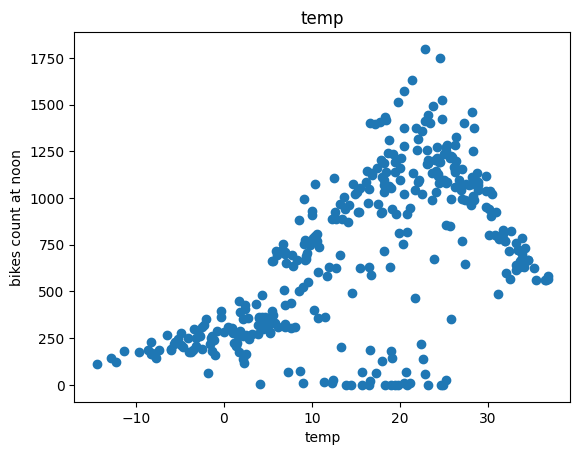

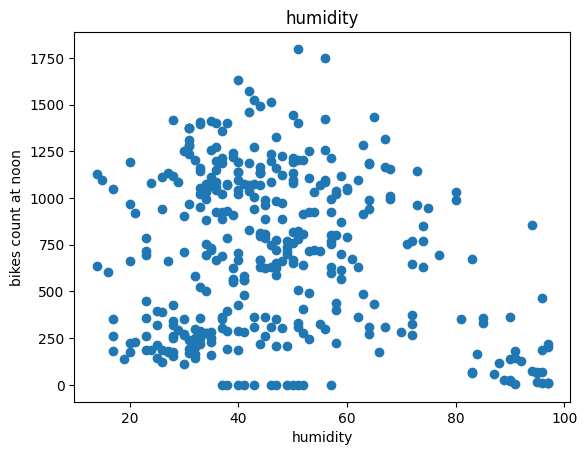

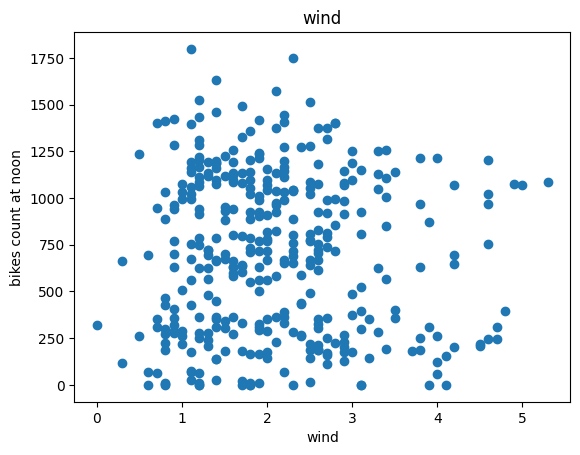

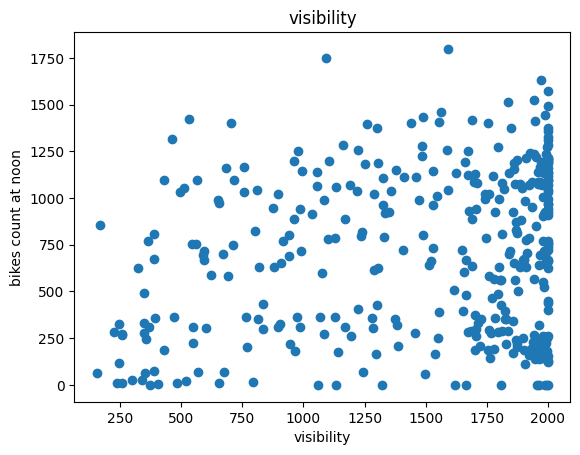

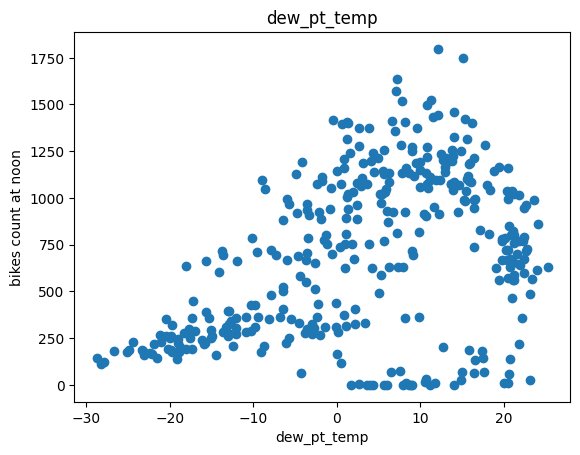

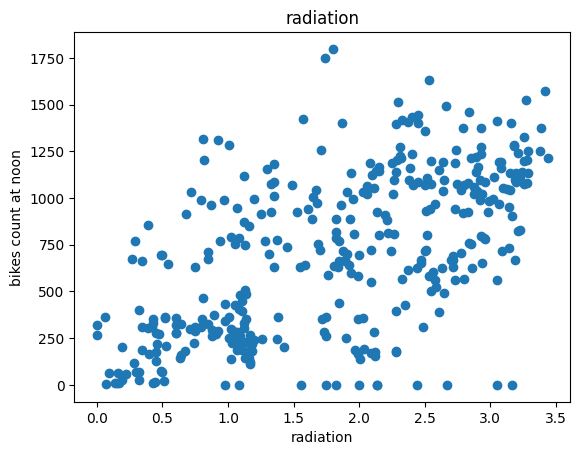

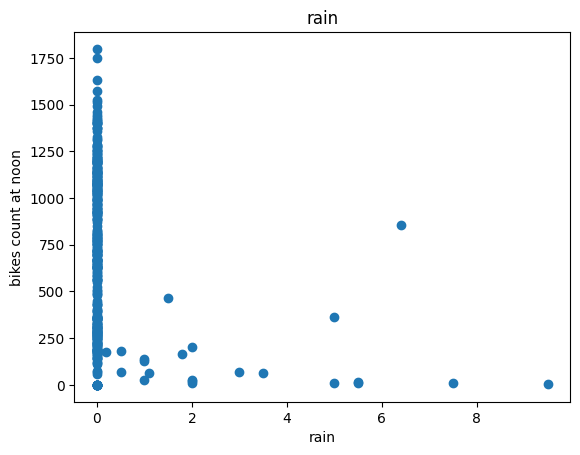

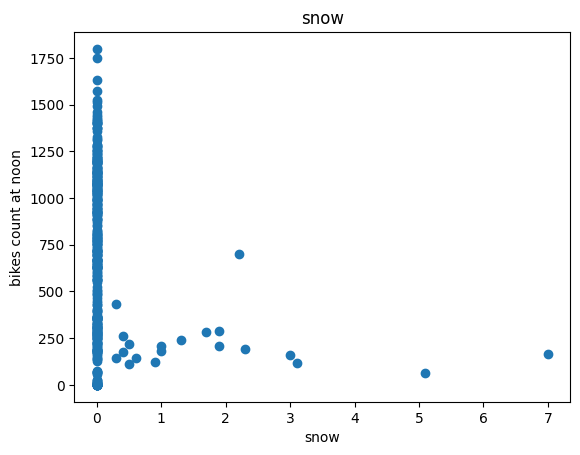

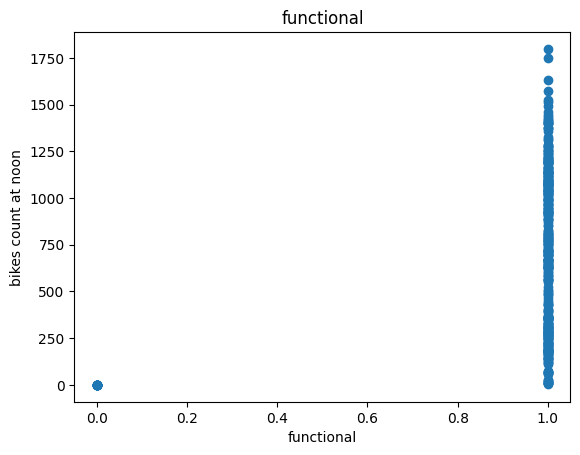

In [172]:
for label in df.columns[1:]:
    plt.scatter(df[label], df['bike_count'])
    plt.xlabel(label)
    plt.ylabel('bikes count at noon')
    plt.title(label)
    plt.show()

get rid of columns that dont affect the bike count or that dont have a linear relationship

In [173]:
df = df.drop(['wind', 'visibility', 'functional'], axis = 1)

train, valid, test split

In [174]:
train, valid, test = np.split(df.sample(frac = 1), [int(0.6 * len(df)), int(0.8 * len(df))])

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


In [175]:
def get_xy(df , y_label, x_label = None):
    df = copy.deepcopy(df)
    if x_label is None:
        X = df[[c for c in df.columns if c != y_label]].values
    else:
        if len(x_label) == 1:
            X = df[x_label[0]].values.reshape(-1, 1)
        else:
            X = df[x_label].values
    y = df[y_label].values.reshape(-1, 1)

    data = np.hstack((X, y))
    return data, X, y

In [176]:
data, X_train_temp, y_train_temp = get_xy(train, 'bike_count', x_label = ['temp'])
data, X_valid_temp, y_valid_temp = get_xy(valid, 'bike_count', x_label = ['temp'])
data, X_test_temp, y_test_temp = get_xy(test, 'bike_count', x_label = ['temp'])

In [177]:
temp_reg = LinearRegression()
temp_reg.fit(X_train_temp, y_train_temp)
print(temp_reg.coef_, temp_reg.intercept_)
print ('r square = ', temp_reg.score(X_test_temp, y_test_temp))

[[20.82989292]] [388.13129787]
r square =  0.27986930305957425


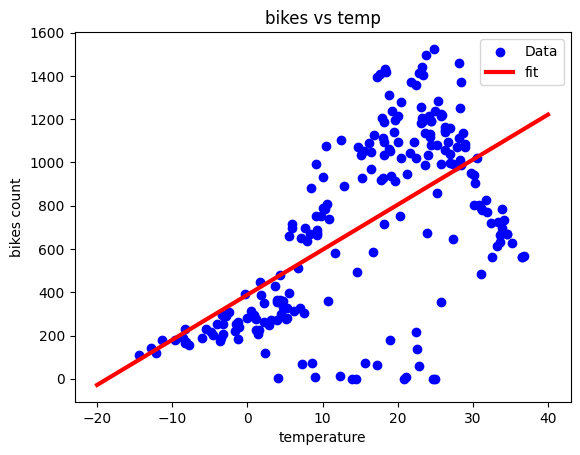

In [178]:
plt.scatter(X_train_temp, y_train_temp, color = 'blue', label = 'Data')
x = tf.linspace(-20, 40, 100)
plt.plot(x, temp_reg.predict(np.array(x).reshape(-1, 1)), color = 'red', linewidth = 3, label = 'fit')
plt.xlabel('temperature')
plt.ylabel('bikes count')
plt.title('bikes vs temp')
plt.legend()
plt.show()

multiple linear regression

In [179]:
train, valid, test = np.split(df.sample(frac = 1), [int(0.6 * len(df)), int(0.8 * len(df))])
data, X_train, y_train = get_xy(train, 'bike_count', x_label = df.columns[1:])
data, X_valid, y_valid = get_xy(valid, 'bike_count', x_label = df.columns[1:])
data, X_test, y_test = get_xy(test, 'bike_count', x_label = df.columns[1:])

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


In [180]:
model = LinearRegression()
model.fit(X_train, y_train)
print(model.coef_, model.intercept_)
print(model.score(X_test, y_test))

[[-26.05195063 -12.24500947  43.02758871 181.70641895 -42.91866102
  -45.71446498]] [1221.6160825]
0.4012833126767591


regression with neural network

In [181]:
temp_normalizer = tf.keras.layers.Normalization(input_shape=(1,), axis = None)
temp_normalizer.adapt(X_train_temp.reshape(-1,))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [182]:
temp_nn_model = tf.keras.Sequential([
    temp_normalizer,
    tf.keras.layers.Dense(1)
])

In [183]:
temp_nn_model.compile(optimizer = tf.keras.optimizers.Adam(0.1), loss = 'mean_squared_error')

In [184]:
history = temp_nn_model.fit(
    X_train_temp.reshape(-1,), y_train_temp,
    epochs = 1000, verbose = 0,
    validation_data = (X_valid_temp, y_valid_temp)
)

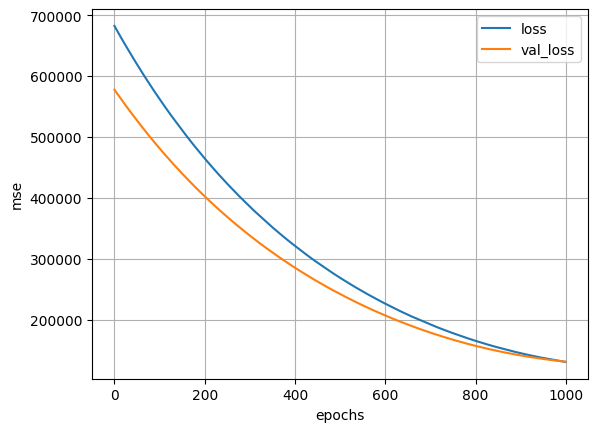

In [185]:
def plot_loss(history):
    plt.plot(history.history['loss'], label = 'loss')
    plt.plot(history.history['val_loss'], label = 'val_loss')
    plt.xlabel('epochs')
    plt.ylabel('mse')
    plt.legend()
    plt.grid(True)
    plt.show()
plot_loss(history)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


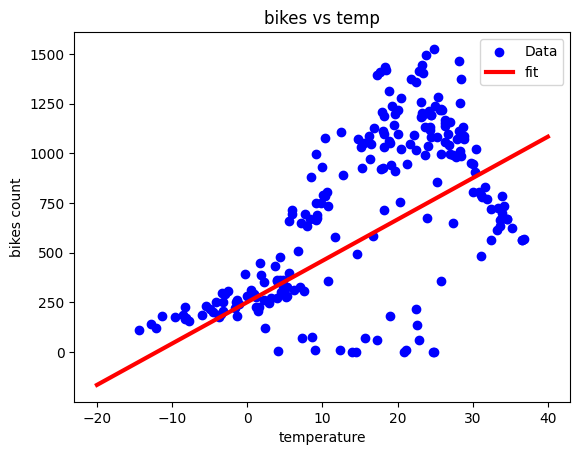

In [186]:
plt.scatter(X_train_temp, y_train_temp, color = 'blue', label = 'Data')
x = tf.linspace(-20, 40, 100)
plt.plot(x, temp_nn_model.predict(np.array(x).reshape(-1, 1)), color = 'red', linewidth = 3, label = 'fit')
plt.xlabel('temperature')
plt.ylabel('bikes count')
plt.title('bikes vs temp')
plt.legend()
plt.show()

neural network

In [187]:
temp_normalizer = tf.keras.layers.Normalization(input_shape=(1,), axis = None)
temp_normalizer.adapt(X_train_temp.reshape(-1,))
nn_model = tf.keras.Sequential([
    tf.keras.layers.Dense(64, activation = 'relu'),
    tf.keras.layers.Dense(64, activation = 'relu'),
    tf.keras.layers.Dense(32, activation = 'relu'),
    tf.keras.layers.Dense(32, activation = 'relu'),
    tf.keras.layers.Dense(32, activation = 'relu'),
    tf.keras.layers.Dense(1)
])
nn_model.compile(optimizer = tf.keras.optimizers.Adam(0.001), loss = 'mean_squared_error')

In [188]:
history = nn_model.fit(
    X_train_temp, y_train_temp,
    epochs = 100, verbose = 0,
    validation_data = (X_valid_temp, y_valid_temp)
)

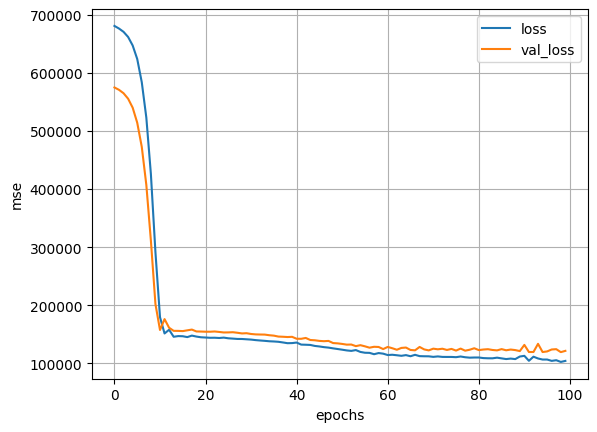

In [189]:
plot_loss(history)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step


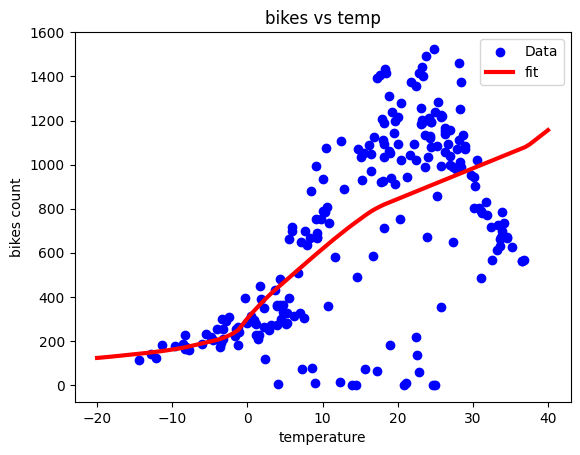

In [190]:
plt.scatter(X_train_temp, y_train_temp, color = 'blue', label = 'Data')
x = tf.linspace(-20, 40, 100)
plt.plot(x, nn_model.predict(np.array(x).reshape(-1, 1)), color = 'red', linewidth = 3, label = 'fit')
plt.xlabel('temperature')
plt.ylabel('bikes count')
plt.title('bikes vs temp')
plt.legend()
plt.show()

In [191]:
all_normalizer = tf.keras.layers.Normalization(input_shape = (6,), axis = -1)
all_normalizer.adapt(X_train)

nn_model = tf.keras.Sequential([
    tf.keras.layers.Dense(32, activation = 'relu'),
    tf.keras.layers.Dense(32, activation = 'relu'),
    tf.keras.layers.Dense(32, activation = 'relu'),

    tf.keras.layers.Dense(1)
])
nn_model.compile(optimizer = tf.keras.optimizers.Adam(0.001), loss = 'mean_squared_error')

In [192]:
history = nn_model.fit(
    X_train, y_train,
    epochs = 100, verbose = 0,
    validation_data = (X_valid, y_valid)
)

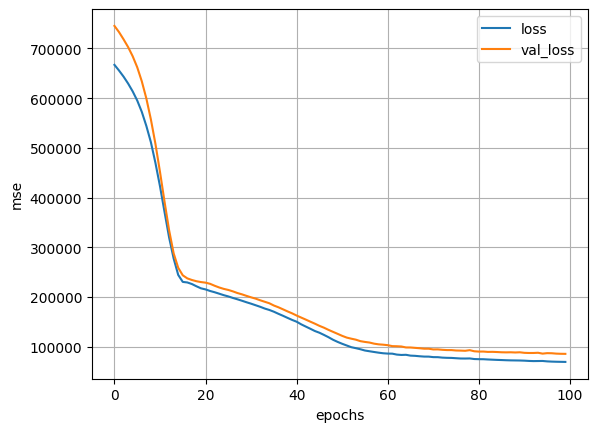

In [193]:
plot_loss(history)

mse for both linear regressio and and nn model

In [194]:
def MSE(y_pred, y_actual):
    return (np.square(y_actual - y_pred)).mean()

In [195]:
y_pred_lr = model.predict(X_test)
y_pred_nn = nn_model.predict(X_test)
lr_mse = MSE(y_pred_lr, y_test)
nn_mse = MSE(y_pred_nn, y_test)
print(lr_mse)
print(nn_mse)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
119323.80907570086
92952.9676651224


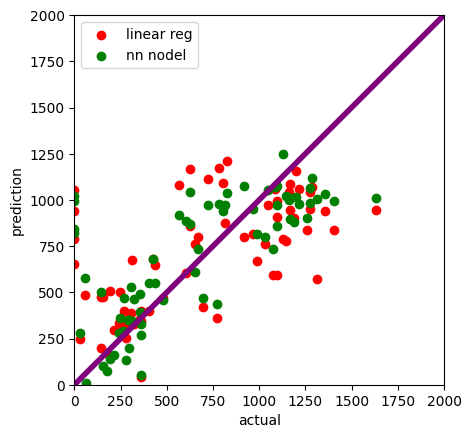

In [196]:
ax = plt.axes(aspect = 'equal')
plt.scatter(y_test, y_pred_lr, color = 'red', label = 'linear reg')
plt.scatter(y_test, y_pred_nn, color = 'green', label = 'nn nodel')
lims = [0, 2000]
plt.xlim(lims)
plt.ylim(lims)
plt.plot(lims, lims, c='purple', linewidth = 4)
plt.xlabel('actual')
plt.ylabel('prediction')
plt.legend()
plt.show()